# BERT Model Evaluation & Inference
### Testing the fine-tuned `bert-base-uncased` model on unseen IMDB reviews



## Step 1 — Imports and Global Variables
Importing the necessary libraries for data manipulation, model loading, and defining the paths for our saved datasets and fine-tuned model.

In [1]:
!pip install -q --upgrade datasets # Upgrade the 'datasets' library quietly (-q) to ensure compatibility

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 19.4 MB/s eta 0:00:00


In [2]:
# Import standard libraries for system operations and array manipulation
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from datasets import load_from_disk
from transformers import BertForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    classification_report
)

from google.colab import drive
drive.mount('/content/drive')

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_PATH  = "/content/drive/MyDrive/Licenta/tokenized_imdb"
BATCH_SIZE = 16  # Set the batch size for the evaluation dataloader

# =============================================================================
# LOAD BEST MODEL FROM COMPARISON EXPERIMENT
# Change MODEL_SAVE_PATH to the best MAX_LENGTH model found in comparison.ipynb
# Options:
#   /content/drive/MyDrive/Licenta/model_maxlen_128
#   /content/drive/MyDrive/Licenta/model_maxlen_256
#   /content/drive/MyDrive/Licenta/model_maxlen_512  <- BEST (highest val acc)
# =============================================================================
MODEL_SAVE_PATH = "/content/drive/MyDrive/Licenta/model_maxlen_512"

print(f"Loading model from: {MODEL_SAVE_PATH}")
model = BertForSequenceClassification.from_pretrained(MODEL_SAVE_PATH)
model = model.to(DEVICE)
model.eval()

# Load and convert manually to TensorDataset
dataset = load_from_disk(SAVE_PATH)
dataset["test"] = dataset["test"].with_format(None)
test    = dataset["test"]

input_ids      = torch.tensor(np.array(test["input_ids"]),      dtype=torch.long)
attention_mask = torch.tensor(np.array(test["attention_mask"]), dtype=torch.long)
labels         = torch.tensor(np.array(test["labels"]),         dtype=torch.long)

test_dataset = TensorDataset(input_ids, attention_mask, labels)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Test samples : {len(test_dataset)}")
print(f"Test batches : {len(test_loader)}")
print("Ready!")


Mounted at /content/drive
Loading model from: /content/drive/MyDrive/Licenta/model_maxlen_512


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Test samples : 7437
Test batches : 465
Ready!


In [12]:
import numpy as np

# Check test set size
print(f"Test set size: {len(test_dataset)}")

# Check first 10 labels
print(f"First 10 labels: {labels[:10].tolist()}")

# Check first input_ids (first few tokens)
print(f"First sample input_ids[:10]: {input_ids[0][:10].tolist()}")

Test set size: 7437
First 10 labels: [1, 1, 1, 1, 0, 0, 1, 1, 0, 0]
First sample input_ids[:10]: [101, 1045, 2134, 1005, 1056, 5987, 2000, 2066, 2023, 2143]


## Step 2 — Batch Evaluation on Test Data
Iterating through the `test_loader` to gather model predictions for the entire test dataset without updating the model weights.

In [3]:
# Initialize empty lists to store all model predictions and true labels
all_preds  = []
all_labels = []

# Disable gradient calculation to save memory and speed up evaluation
with torch.no_grad():
    for input_ids, attention_mask, labels in test_loader:
        input_ids      = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask) # Forward pass: get the model's output (logits) for the current batch
        preds   = torch.argmax(outputs.logits, dim=1) # Get the predicted class by finding the index with the highest logit value

# Convert predictions and labels to NumPy arrays and append to our master lists
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(f"Done! {len(all_preds)} predictions")

Done! 7437 predictions


## Step 3 — Classification Report and Confusion Matrix Visualization


In [4]:
accuracy  = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds)
recall    = recall_score(all_labels, all_preds)
f1        = f1_score(all_labels, all_preds)

print("=" * 45)
print("         FINAL TEST SET RESULTS")
print("=" * 45)
print(f"  Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"  Precision : {precision:.4f}  ({precision*100:.2f}%)")
print(f"  Recall    : {recall:.4f}  ({recall*100:.2f}%)")
print(f"  F1 Score  : {f1:.4f}  ({f1*100:.2f}%)")
print("=" * 45)

print("\nDetailed Classification Report:")
print(classification_report(
    all_labels, all_preds,
    target_names=["Negative", "Positive"]
))

         FINAL TEST SET RESULTS
  Accuracy  : 0.9793  (97.93%)
  Precision : 0.9748  (97.48%)
  Recall    : 0.9842  (98.42%)
  F1 Score  : 0.9795  (97.95%)

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.98      0.97      0.98      3705
    Positive       0.97      0.98      0.98      3732

    accuracy                           0.98      7437
   macro avg       0.98      0.98      0.98      7437
weighted avg       0.98      0.98      0.98      7437



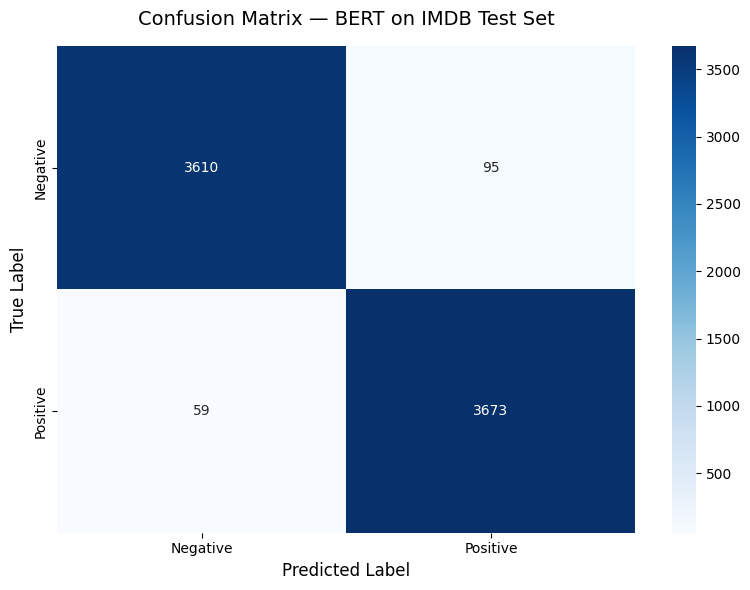

Confusion matrix saved to Drive!


In [5]:
cm = confusion_matrix(all_labels, all_preds) # Calculate the confusion matrix based on the true labels and the model's predictions

plt.figure(figsize=(8, 6))
# Create a heatmap using seaborn to visualize the confusion matrix
sns.heatmap(
    cm,
    annot=True, # displays the numbers in the cells
    fmt="d", # formats them as integers
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)
plt.title("Confusion Matrix — BERT on IMDB Test Set", fontsize=14, pad=15)
plt.ylabel("True Label", fontsize=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/confusion_matrix.png", dpi=150)
plt.show()
print("Confusion matrix saved to Drive!")

## Step 4 — Data Preparation and Dataset Alignment


In [6]:
# Load test texts from the pre-saved CSV file.
# This file was created during preprocessing and contains the EXACT texts
# from the same test split used during training — ensuring correct alignment.
# Using test_texts.csv avoids re-running the split and guarantees consistency.

import pandas as pd
import os

TEST_TEXTS_PATH = "/content/drive/MyDrive/Licenta/test_texts.csv"

# Load the test texts CSV saved during preprocessing
test_df    = pd.read_csv(TEST_TEXTS_PATH)
test_texts = test_df["text"].tolist()

print(f"Test texts loaded from CSV : {len(test_texts)}")
print(f"First review preview       : {test_texts[0][:150]}...")


Test texts loaded from CSV : 7437
First review preview       : When I was a child my grandmother took me to see this movie. And I fell in love with it. I admired Dorothy Dandridge so very much and wanted to be lik...


## Step 5 - Calculate Evaluation Metrics and Error Rates

In [7]:
wrong_indices  = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l] # Find the indices where the prediction (p) does not match the actual label (l)
correct_indices = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p == l] # Find the indices where the prediction (p) correctly matches the actual label (l)

# Map numerical labels to their human-readable string representations
label_map = {0: "Negative", 1: "Positive"}

print(f"Total errors   : {len(wrong_indices)} / {len(all_labels)}")
print(f"Error rate     : {len(wrong_indices)/len(all_labels)*100:.2f}%")
print(f"Correct        : {len(correct_indices)}")

Total errors   : 154 / 7437
Error rate     : 2.07%
Correct        : 7283


## Step 6 - Display Misclassified Examples

In [8]:
print("=" * 70)
print("MISCLASSIFIED EXAMPLES")
print("=" * 70)

# Iterate through the first 5 indices of incorrectly predicted examples
for idx in wrong_indices[:5]:
    text       = test_texts[idx]
    true_label = label_map[all_labels[idx]]
    pred_label = label_map[all_preds[idx]]

    print(f"\nExample #{idx}")
    print(f"  True Label : {true_label}")
    print(f"  Predicted  : {pred_label}")
    print(f"  Text       : {text[:300]}...")
    print("-" * 70)

MISCLASSIFIED EXAMPLES

Example #67
  True Label : Negative
  Predicted  : Positive
  Text       : We rented five movies for New Year's Eve weekend and watched this one first. All I can say is that there was no place to go but up after watching this one. It was pointless and vulgar. Harvey Keitel's script must have been easy to write -- just make two out every three words a curse word. Andie McDo...
----------------------------------------------------------------------

Example #99
  True Label : Negative
  Predicted  : Positive
  Text       : Wow. What a terrible adaptation of a beautiful novel. Here are just a few gripes. - The screenwriter eliminated two major characters from the book. - Plot has been grotesquely altered. - Voiceovers sound as if they were directly lifted from written passages (which may read well but are not the same ...
----------------------------------------------------------------------

Example #251
  True Label : Negative
  Predicted  : Positive
  Text       

## Step 7 - Analyze and Plot Error Distribution by Review Length

Average length of WRONG predictions   : 228 words
Average length of CORRECT predictions : 228 words


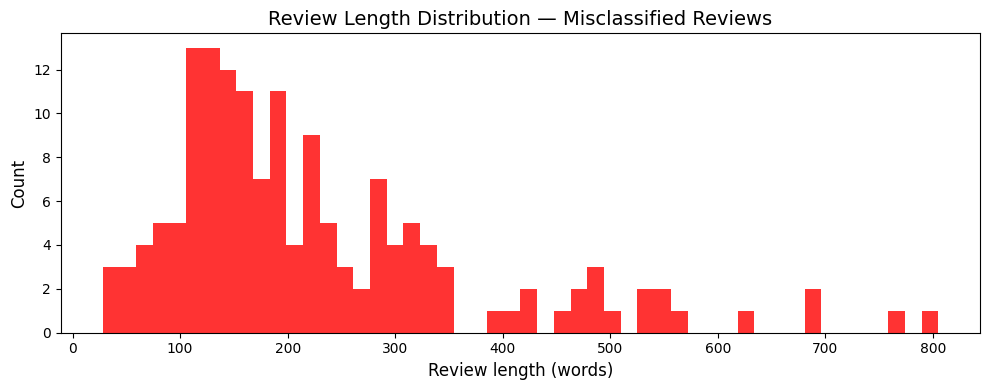

Misclassified plot saved!


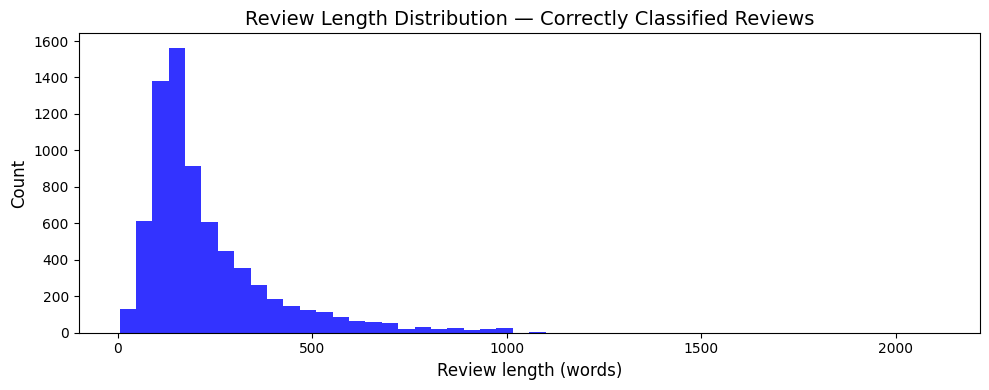

Correct plot saved!


In [9]:
# Check if longer reviews have more errors
wrong_lengths   = [len(test_texts[i].split()) for i in wrong_indices]
correct_lengths = [len(test_texts[i].split()) for i in correct_indices]

print(f"Average length of WRONG predictions   : {sum(wrong_lengths)/len(wrong_lengths):.0f} words")
print(f"Average length of CORRECT predictions : {sum(correct_lengths)/len(correct_lengths):.0f} words")

# Plot 1 — Misclassified reviews only
plt.figure(figsize=(10, 4))
plt.hist(wrong_lengths, bins=50, color="red", alpha=0.8)
plt.xlabel("Review length (words)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.title("Review Length Distribution — Misclassified Reviews", fontsize=14)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/error_length_misclassified.png", dpi=150)
plt.show()
print("Misclassified plot saved!")

# Plot 2 — Correct reviews only
plt.figure(figsize=(10, 4))
plt.hist(correct_lengths, bins=50, color="blue", alpha=0.8)
plt.xlabel("Review length (words)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.title("Review Length Distribution — Correctly Classified Reviews", fontsize=14)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/error_length_correct.png", dpi=150)
plt.show()
print("Correct plot saved!")


## Step 8 - Analyze Impact of Irony and Sarcasm on Model Performance

In [10]:
# Define a list of keywords commonly associated with irony or sarcasm
irony_keywords = [
    "supposedly", "apparently", "brilliant", "genius",
    "masterpiece", "wow", "amazing", "sure", "right",
    "of course", "obviously", "great job", "well done"
]

# Initialize empty lists to store indices of reviews with potential irony
irony_errors   = []
irony_correct  = []

# Iterate through indices of incorrectly classified reviews (errors)
for idx in wrong_indices:
    text_lower = test_texts[idx].lower() # Convert text to lowercase for case-insensitive keyword matching
    if any(kw in text_lower for kw in irony_keywords): # Check if any of the predefined irony keywords exist in the text
        irony_errors.append(idx)

# Iterate through indices of correctly classified reviews
for idx in correct_indices:
    text_lower = test_texts[idx].lower() # Convert text to lowercase for case-insensitive keyword matching
    if any(kw in text_lower for kw in irony_keywords): # Check if any of the predefined irony keywords exist in the text
        irony_correct.append(idx)

# Calculate the total number of reviews containing potential irony keywords
total_irony = len(irony_errors) + len(irony_correct)
print(f"Reviews with potential irony/sarcasm keywords : {total_irony}")
print(f"  Misclassified : {len(irony_errors)} "
      f"({len(irony_errors)/total_irony*100:.1f}%)")
print(f"  Correct       : {len(irony_correct)} "
      f"({len(irony_correct)/total_irony*100:.1f}%)")

print("\nExample of potentially ironic misclassified review:")
if irony_errors:
    idx  = irony_errors[0]
    print(f"  True: {label_map[all_labels[idx]]} | "
          f"Predicted: {label_map[all_preds[idx]]}")
    print(f"  Text: {test_texts[idx][:300]}...")

Reviews with potential irony/sarcasm keywords : 3477
  Misclassified : 60 (1.7%)
  Correct       : 3417 (98.3%)

Example of potentially ironic misclassified review:
  True: Negative | Predicted: Positive
  Text: Wow. What a terrible adaptation of a beautiful novel. Here are just a few gripes. - The screenwriter eliminated two major characters from the book. - Plot has been grotesquely altered. - Voiceovers sound as if they were directly lifted from written passages (which may read well but are not the same ...


## Step 9 — Save Final Metrics to CSV
Saving all evaluation metrics and hyperparameters to a CSV file on Google Drive for future reference.


In [11]:
# Save final test set metrics to Google Drive.
# Drive is already mounted in Step 1 — os.makedirs ensures folder exists.

import os
import pandas as pd

os.makedirs("/content/drive/MyDrive/Licenta", exist_ok=True)

metrics = {
    "Accuracy":      [round(accuracy, 4)],
    "Precision":     [round(precision, 4)],
    "Recall":        [round(recall, 4)],
    "F1 Score":      [round(f1, 4)],
    "MAX_LENGTH":    [512],
    "Epochs":        [3],
    "Batch Size":    [16],
    "Learning Rate": [2e-5],
}

pd.DataFrame(metrics).to_csv(
    "/content/drive/MyDrive/Licenta/final_metrics.csv", index=False
)
print("Metrics saved to Drive!")


Metrics saved to Drive!
